# **AI Guild Fall 2026: Build Your Own GPT Model!**

`Alex E. Sanchez` :)

### Imports

In [ ]:
%pip install -q "jax==0.7.2" "flax==0.12.0" "optax==0.2.6" "datasets==4.8.5" "transformers==4.57.6" "huggingface-hub==0.36.2" "safetensors==0.8.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 466.3/466.3 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 367.8/367.8 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 1.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires hu

In [ ]:
import json
import os
from dataclasses import dataclass
from pathlib import Path

os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"

import jax
import jax.numpy as jnp
import numpy as np
import optax
from datasets import load_dataset
from flax import nnx
from huggingface_hub import snapshot_download
from safetensors.numpy import load_file
from transformers import GPT2TokenizerFast

from einops import rearrange
from beartype import beartype

tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")

print("JAX backend:", jax.default_backend())
print("Vocabulary size:", tokenizer.vocab_size)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

JAX backend: gpu
Vocabulary size: 50257


## **Our Dataset**

In [ ]:
dataset = load_dataset(
    "andrewelawrence/writingPrompts-merged",
    split="train",
    revision="2e3fc387744e21e3adbbc2f73a960c164b248ab8"
)

README.md:   0%|          | 0.00/736 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet:   0%|          | 0.00/302M [00:00<?, ?B/s]

data/train-00001-of-00002.parquet:   0%|          | 0.00/302M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

In [ ]:
print(f"Stories: {len(dataset):,}")
print("Columns:", dataset.column_names)
print("Prompt:", dataset[0]["prompt"])
print("Story opening:", dataset[0]["story"][:500])

Stories: 303,358
Columns: ['prompt', 'story']
Prompt: [ WP ] Leonardo DiCaprio in a fit of rage begins to torpedo his own career by deliberately acting poorly and taking on bad films . He finally wins an oscar for starring in Paul Blart : Mall Cop 3 .

Story opening: The wet marble floor pressed on his cheek like a thousand hands slapping his face frozen in time. Smattering piss of rain ignored his indignant mumblings. His eyes fluttered. Pins and needs ran from finger to shoulder as he pushed back against the floor, contorting his aching body into a cross legged position. Last night was bad. He gathered that. His routine dullness of though crept inwards from the edges of his mind toward the black mist that veiled his most recent memories. He struggled to re


In [ ]:
example = "The door had been locked for a hundred years."
token_ids = tokenizer.encode(example, add_special_tokens=False)

print("Text:", example)
print("Token IDs:", token_ids)
print("Token pieces:", tokenizer.convert_ids_to_tokens(token_ids))

Text: The door had been locked for a hundred years.
Token IDs: [464, 3420, 550, 587, 8970, 329, 257, 3470, 812, 13]
Token pieces: ['The', 'Ġdoor', 'Ġhad', 'Ġbeen', 'Ġlocked', 'Ġfor', 'Ġa', 'Ġhundred', 'Ġyears', '.']


---

## **Building the Model**

### GPT2-Small (124M) Configuration

In [ ]:
@dataclass(frozen=True)
class GuildGPTConfig:
    max_seq_len: int = 1024
    vocab_size: int = 50257
    n_layers: int = 12
    n_heads: int = 12
    hidden_size: int = 768
    mlp_hidden_size: int | None = 4 * 768

## The Transformer Modules

1. Multi-Head Self-Attention

2. Multi-Layer Perceptron

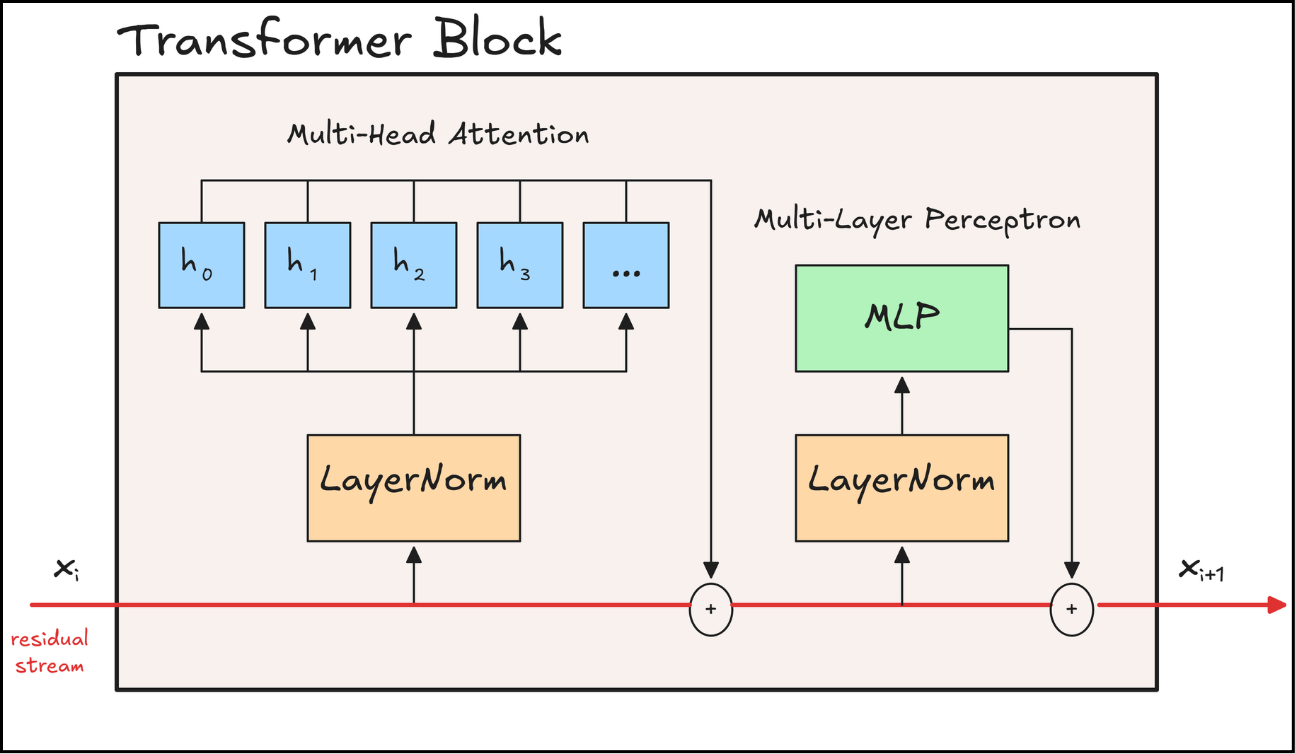

In [ ]:
class MultiHeadSelfAttention(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.n_heads = config.n_heads
        self.head_size = config.hidden_size // config.n_heads
        self.output_size = config.hidden_size
        self.hidden_size = config.hidden_size

        assert self.hidden_size % self.n_heads == 0

        self.Wq = nnx.Linear(config.hidden_size, config.hidden_size, use_bias=False, rngs=rngs)
        self.Wk = nnx.Linear(config.hidden_size, config.hidden_size, use_bias=False, rngs=rngs)
        self.Wv = nnx.Linear(config.hidden_size, config.hidden_size, use_bias=False, rngs=rngs)
        self.Wo = nnx.Linear(config.hidden_size, config.hidden_size, use_bias=False, rngs=rngs)


    def __call__(self, x):
        batch, seq_len, _ = x.shape

        q, k, v = self.Wq(x), self.Wk(x), self.Wv(x)

        # Split into heads: (b, n, h) -> (b, heads, n, head_size)
        def mha_reshape(tensor):
            return rearrange(tensor, 'b n (heads d) -> b heads n d', heads=self.n_heads)
        Q, K, V = map(mha_reshape, (q, k, v))

        # Scaled Dot Product Attention
        # For QKᵀ we want (n, head_size) @ (head_size, n)
        scale = self.head_size ** -0.5
        attention_weights = jnp.einsum('b h i d, b h j d -> b h i j', Q, K)
        attention_weights = attention_weights * scale

        # Causal mask:
        #     k0  k1  k2  k3
        # q0 [■   □   □   □ ]
        # q1 [■   ■   □   □ ]
        # q2 [■   ■   ■   □ ]
        # q3 [■   ■   ■   ■ ]
        causal_mask = jnp.tril(jnp.ones((seq_len, seq_len), dtype=jnp.bool_))

        # All □ become -∞
        attention_weights = jnp.where(causal_mask, attention_weights, float('-inf'))
        attention_weights = nnx.softmax(attention_weights, axis=-1)

        out = jnp.einsum('b h i j, b h j d -> b h i d', attention_weights, V)

        # Merge heads: (b, heads, n, head_size) -> (b, n, h)
        out = rearrange(out, 'b heads n d -> b n (heads d)')

        return self.Wo(out)

In [ ]:
class MultiLayerPerceptron(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.fc1 = nnx.Linear(config.hidden_size, config.mlp_hidden_size, use_bias=True, rngs=rngs)
        self.fc2 = nnx.Linear(config.mlp_hidden_size, config.hidden_size, use_bias=True, rngs=rngs)

    def __call__(self, x):
        x = self.fc1(x)
        x = jax.nn.gelu(x)
        x = self.fc2(x)
        return x

In [ ]:
class TransformerLayer(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.mhsa = MultiHeadSelfAttention(config, rngs=rngs)
        self.mlp = MultiLayerPerceptron(config, rngs=rngs)
        self.ln1 = nnx.LayerNorm(config.hidden_size, rngs=rngs)
        self.ln2 = nnx.LayerNorm(config.hidden_size, rngs=rngs)

    def __call__(self, x):
        x = x + self.mhsa(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

### The Full Model!

In [ ]:
class GuildGPT(nnx.Module):
    def __init__(self, config: GuildGPTConfig, rngs: nnx.Rngs):
        self.config = config
        self.wte = nnx.Embed(config.vocab_size, config.hidden_size, rngs=rngs)
        self.wpe = nnx.Embed(config.max_seq_len, config.hidden_size, rngs=rngs)
        self.layers = nnx.List([TransformerLayer(config, rngs) for _ in range(config.n_layers)])
        self.ln_f = nnx.LayerNorm(config.hidden_size, rngs=rngs)

    def __call__(self, input_ids):
        _, seq_len = input_ids.shape

        positions = jnp.arange(seq_len)

        # Token Embeddings + Positional Embeddings
        x = self.wte(input_ids) + self.wpe(positions)

        # Pass the hidden state through our layers
        for layer in self.layers:
            x = layer(x)

        x = self.ln_f(x)

        # Weight tying!
        logits = self.wte.attend(x)

        return logits

### Generating a Sentence!

In [ ]:
def generate(model: GuildGPT, prompt: str, max_new_tokens: int = 10, temperature: float = 0.8, top_k: int = 50) -> str:
    input_ids = jnp.array(tokenizer.encode(prompt))[None, :]
    key = jax.random.PRNGKey(42)

    for _ in range(max_new_tokens):
        logits = model(input_ids[:, -model.config.max_seq_len:])
        logits = logits[:, -1, :] / temperature

        # Top-k sampling
        top_logits, top_ids = jax.lax.top_k(logits, top_k)

        key, subkey = jax.random.split(key)
        sample = jax.random.categorical(subkey, top_logits, axis=-1)

        next_token = jnp.take_along_axis(
            top_ids, sample[:, None], axis=-1
        )

        if int(next_token[0, 0]) == tokenizer.eos_token_id:
            break

        input_ids = jnp.concatenate([input_ids, next_token], axis=1)

    return tokenizer.decode(
        np.asarray(input_ids[0]),
        skip_special_tokens=True
    )

### Our Current, Random (Dumb) Model

In [ ]:
config = GuildGPTConfig()
dumb_model = GuildGPT(config, nnx.Rngs(42))
print(generate(dumb_model, "The quick brown fox"))

The quick brown fox revered Palo interf Cover� Marcflush sleepy Ravthy


## **Training a GPT Model**

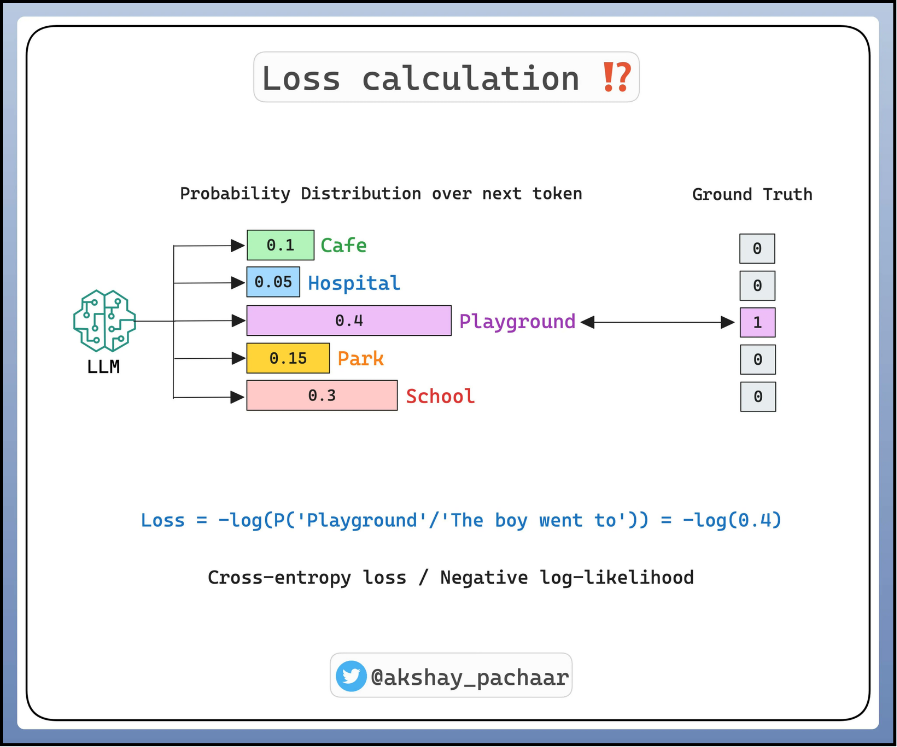

In [ ]:
def compute_loss(model, input_ids):
    logits = model(input_ids[:, :-1])
    targets = input_ids[:, 1:]

    # Cross-Entropy
    loss = optax.softmax_cross_entropy_with_integer_labels(
        logits=logits.astype(jnp.float32),
        labels=targets
    )

    return loss.mean()

In [ ]:
@nnx.jit
def train_step(model: GuildGPT, optimizer: nnx.Optimizer, input_ids):
    loss, grads = nnx.value_and_grad(compute_loss)(model, input_ids)
    optimizer.update(model, grads)
    return loss

## **Loading our Model**

In [ ]:
%pip install -q "guildgpt @ git+https://github.com/thealepo/guild-gpt.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 563.1/563.1 kB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.5/176.5 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 141.8/141.8 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 19.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.4.0 requires opentelemetry-api<=1.42.1,>

In [ ]:
from guildgpt.hub import load_from_hub

trained_model, tokenizer = load_from_hub("thealepo/GuildGPT")
print("Trained model loaded!")

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/199 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

Trained model loaded!


### Try it out!

In [ ]:
print(generate(trained_model, "Once upon a time,", max_new_tokens=100))

Once upon a time, there will be no more! ” 
 
 “ But I can ’ t be there! Why am I here? ” 
 
 The man looked at the man, and he could almost see the fear in his eyes. He had never been as mad as he felt when he saw the horror of what he had just witnessed. It was then, that everything that had felt like it had been gone for the first time in centuries, a new world, a new
